In [32]:
# =====================================================
# 🧠 PHARMA WEEKLY SALES FORECAST – FINAL NOTEBOOK
# =====================================================

# =============== 1️⃣ SETUP & IMPORTS ==================
import os, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from mlflow.tracking import MlflowClient
from prophet import Prophet
from xgboost import XGBRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from datetime import timedelta
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("coolwarm")
print("✅ Environment ready | Imports successful")


✅ Environment ready | Imports successful


In [33]:
# =============== 2️⃣ LOAD & CLEAN DATA =================
data_path = r"F:\study\mlops\salesweekly.csv"
df = pd.read_csv(data_path)

# Rename & format
df.rename(columns={'datum': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Aggregate all product codes into total weekly sales
cols_to_sum = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']
df['Total_Sales'] = df[cols_to_sum].sum(axis=1)

# Clean + filter
df = df.sort_values('Date').dropna(subset=['Total_Sales'])
df = df[df['Total_Sales'] > 0].reset_index(drop=True)
df.rename(columns={'Date':'ds','Total_Sales':'y'}, inplace=True)

print(f"✅ Data verified — {len(df)} weekly records, no nulls")
display(df.head())
print("\n📊 Summary:\n", df.describe())


✅ Data verified — 302 weekly records, no nulls


,ds,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,y
0,2014-01-05,14.00,11.67,21.3,185.95,41.0,0.0,32.0,7.0,312.92
1,2014-01-12,29.33,12.68,37.9,190.70,88.0,5.0,21.0,7.2,391.81
2,2014-01-19,30.67,26.34,45.9,218.40,80.0,8.0,29.0,12.0,450.31
3,2014-01-26,34.00,32.37,31.5,179.60,80.0,8.0,23.0,10.0,398.47
4,2014-02-02,31.02,23.35,20.7,159.88,84.0,12.0,29.0,12.0,371.95



📊 Summary:
                         ds       M01AB       M01AE       N02BA       N02BE  \
count                  302  302.000000  302.000000  302.000000  302.000000   
mean   2016-11-23 12:00:00   35.102441   27.167611   27.060295  208.627161   
min    2014-01-05 00:00:00    7.670000    6.237000    3.500000   86.250000   
25%    2015-06-15 18:00:00   29.387500   22.387500   21.300000  149.300000   
50%    2016-11-23 12:00:00   34.565000   26.789500   26.500000  198.300000   
75%    2018-05-04 06:00:00   40.175000   31.046500   32.475000  252.471500   
max    2019-10-13 00:00:00   65.330000   53.571000   60.125000  546.899000   
std                    NaN    8.617106    7.043491    8.086458   76.069221   

             N05B        N05C         R03         R06           y  
count  302.000000  302.000000  302.000000  302.000000  302.000000  
mean    61.740853    4.138935   38.439811   20.224561  422.501668  
min     18.000000    0.000000    2.000000    1.000000  153.507000  
25%     47.0

📆 Train: 256 weeks | Test: 46 weeks


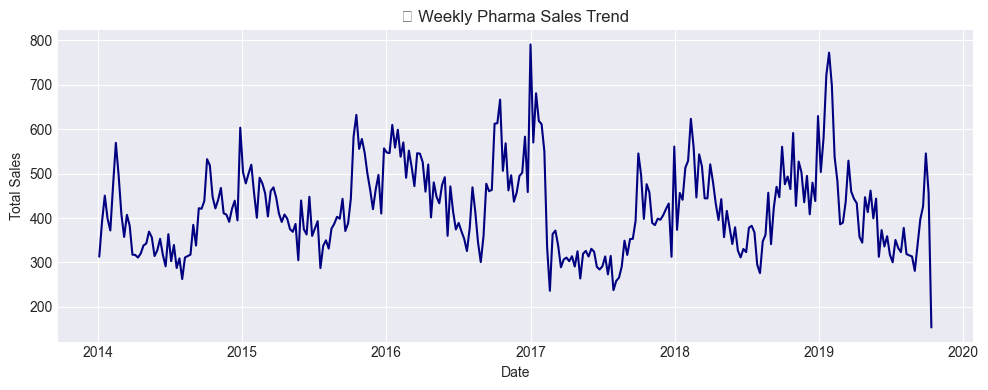

In [34]:
# =============== 3️⃣ TRAIN / TEST SPLIT + EDA ===========
train_size = int(len(df)*0.85)
train, test = df.iloc[:train_size], df.iloc[train_size:]
print(f"📆 Train: {len(train)} weeks | Test: {len(test)} weeks")

plt.figure(figsize=(10,4))
plt.plot(df['ds'], df['y'], color='navy')
plt.title("📊 Weekly Pharma Sales Trend")
plt.xlabel("Date"); plt.ylabel("Total Sales")
plt.tight_layout(); plt.show()


In [35]:
# =============== 4️⃣ MLFLOW SETUP ======================
EXPERIMENT_NAME = "Pharma Weekly Forecast (Final)"
mlflow.set_experiment(EXPERIMENT_NAME)
client = MlflowClient()

print("🔗 MLflow experiment:", EXPERIMENT_NAME)


🔗 MLflow experiment: Pharma Weekly Forecast (Final)


In [36]:
# =============== 5️⃣ DEFINE MODELS ======================
MODELS = [
    ("Holt-Winters Adaptive",
     lambda: ExponentialSmoothing(train['y'], trend="add",
                                  seasonal=None,
                                  initialization_method="estimated").fit(),
     lambda m,s: m.forecast(s)),

    ("ARIMA(1,1,1)",
     lambda: ARIMA(train['y'], order=(1,1,1)).fit(),
     lambda m,s: m.forecast(s)),

    ("Prophet Tuned",
     lambda: Prophet(weekly_seasonality=True, yearly_seasonality=True,
                     changepoint_prior_scale=0.1,
                     seasonality_mode='multiplicative').fit(train),
     lambda m,s: m.predict(test)['yhat'])
]


In [37]:
# =============== 6️⃣ FEATURE ENGINEERING + XGBOOST ======
def create_lag_features(df, lags=[1,2,3,4]):
    df = df.copy()
    for lag in lags:
        df[f'lag_{lag}'] = df['y'].shift(lag)
    df['rolling_mean_4'] = df['y'].rolling(4).mean()
    return df.dropna()

df_lagged = create_lag_features(df)
train_lagged, test_lagged = df_lagged.iloc[:train_size], df_lagged.iloc[train_size:]

XGB_MODEL = XGBRegressor(
    n_estimators=400, learning_rate=0.05, max_depth=6,
    subsample=0.9, colsample_bytree=0.9, random_state=42
)
MODELS.append(("XGBoost Lag-Enhanced", XGB_MODEL, None))


In [ ]:
# --- 7️⃣ TRAIN + LOG ALL MODELS ---
results = []

# Close any leftover runs
if mlflow.active_run():
    mlflow.end_run()

for name, func, predict_func in MODELS:
    print(f"\n🚀 Training: {name}")
    with mlflow.start_run(run_name=name):
        ...

        if "XGBoost" in name:
            features = [c for c in train_lagged.columns if c not in ['ds','y']]
            X_train, y_train = train_lagged[features], train_lagged['y']
            X_test,  y_test  = test_lagged[features],  test_lagged['y']
            model = func
            model.fit(X_train, y_train)
            preds = model.predict(X_test)
            actuals = y_test.values
        else:
            model = func()
            preds = predict_func(model, len(test))
            actuals = test['y'].values

        mae  = mean_absolute_error(actuals, preds)
        rmse = np.sqrt(mean_squared_error(actuals, preds))
        r2   = r2_score(actuals, preds)

        mlflow.log_metrics({"MAE":mae,"RMSE":rmse,"R2":r2})
        mlflow.log_params({"Model":name})

        # Visualization
        plt.figure(figsize=(10,5))
        plt.plot(train['ds'], train['y'], label="Train")
        plt.plot(test['ds'], test['y'], label="Actual")
        plt.plot(test['ds'][:len(preds)], preds, label="Forecast", linestyle="--")
        plt.title(f"{name} — Weekly Sales Forecast")
        plt.legend(); plt.tight_layout()
        plt.savefig(f"{name}_forecast.png"); plt.close()
        mlflow.log_artifact(f"{name}_forecast.png")

        results.append({"Model":name,"MAE":mae,"RMSE":rmse,"R2":r2})

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print("\n🏆 Model Performance Summary:")
display(results_df)
best = results_df.iloc[0]
print(f"\n🏁 Best Model: {best['Model']} (R²={best['R2']:.3f})")

if "XGBoost" in best['Model']:
    joblib.dump(model, "best_model_xgb.pkl")
    print("💾 Saved best model as best_model_xgb.pkl")



🚀 Training: Holt-Winters Adaptive

🚀 Training: ARIMA(1,1,1)


18:26:16 - cmdstanpy - INFO - Chain [1] start processing



🚀 Training: Prophet Tuned


18:26:17 - cmdstanpy - INFO - Chain [1] done processing



🚀 Training: XGBoost Lag-Enhanced

🏆 Model Performance Summary:


,Model,MAE,RMSE,R2
3,XGBoost Lag-Enhanced,22.477582,37.461724,0.907357
2,Prophet Tuned,88.190362,115.824560,0.042488
1,"ARIMA(1,1,1)",97.647732,123.569230,-0.089842
0,Holt-Winters Adaptive,107.194973,131.618381,-0.236448



🏁 Best Model: XGBoost Lag-Enhanced (R²=0.907)
💾 Saved best model as best_model_xgb.pkl
